# CF-Miner: Price of canceled bookings

**Author:** Pavlo Romanovyč Prytula

We look for segments of canceled bookings in which expensive bookings dominate and then check whether
they are more expensive than the bookings of the same segment that were not canceled.
This task complements `canceled_lead_time_increase.ipynb`, which looks at lead time instead of price.

**Question:** In which segments are canceled bookings mostly expensive, and are they more expensive
than the bookings of the same segment that were not canceled?
Does this differ between the City Hotel and the Resort Hotel?

| Part | Setting |
| --- | --- |
| Attribute for histogram (A) | `adr_cat` |
| Condition (C) | `hotel`, `season`, `guests_cat`, `meal` (subset, 1) |
| Condition length | 1–2 |
| Data | canceled bookings only (`is_canceled = 1`, filtered beforehand) |
| Quantifiers | `S_Up ≥ 3`, `Base ≥ 1000` |
| Check after mining | canceled vs. not canceled bookings of the found segments |

In [1]:
import pandas as pd
from cleverminer import cleverminer

bookings = pd.read_csv("../../data/processed/hotel_bookings_categorized.csv", dtype=str)

df = bookings[bookings["is_canceled"] == "1"]
df = df[[
    "hotel",
    "season",
    "guests_cat",
    "meal",
    "adr_cat",
]]

print("Canceled bookings:", len(df))

Cleverminer version  1.2.8
Canceled bookings: 44171


## Choosing the quantifiers

Price of canceled bookings in both hotels as a whole and in three example segments
(`n` = number of canceled bookings).

In [2]:
canceled = bookings["is_canceled"] == "1"

segments = {
    "City Hotel (all)": bookings["hotel"] == "City Hotel",
    "Resort Hotel (all)": bookings["hotel"] == "Resort Hotel",
    "City Hotel, 3+ guests": (bookings["hotel"] == "City Hotel") & (bookings["guests_cat"] == "3+"),
    "Resort Hotel, 3+ guests": (bookings["hotel"] == "Resort Hotel") & (bookings["guests_cat"] == "3+"),
    "Resort Hotel, summer": (bookings["hotel"] == "Resort Hotel") & (bookings["season"] == "3_summer"),
}

shapes = pd.DataFrame({
    name: bookings.loc[mask & canceled, "adr_cat"].value_counts(normalize=True)
    for name, mask in segments.items()
}).T.sort_index(axis=1).fillna(0).round(3)
shapes["n"] = [(mask & canceled).sum() for mask in segments.values()]

shapes

adr_cat,1_0,2_1-75,3_76-125,4_126-200,5_200+,n
City Hotel (all),0.003,0.240,0.504,0.233,0.019,33061
Resort Hotel (all),0.006,0.419,0.267,0.194,0.113,11110
"City Hotel, 3+ guests",0.001,0.006,0.198,0.644,0.149,3487
"Resort Hotel, 3+ guests",0.012,0.054,0.209,0.379,0.346,1584
"Resort Hotel, summer",0.002,0.063,0.215,0.422,0.298,4078


,0 → 1-75,1-75 → 76-125,76-125 → 126-200,126-200 → 200+
City Hotel (all),True,True,False,False
Resort Hotel (all),True,False,False,False
"City Hotel, 3+ guests",True,True,True,False
"Resort Hotel, 3+ guests",True,True,True,False
"Resort Hotel, summer",True,True,True,False


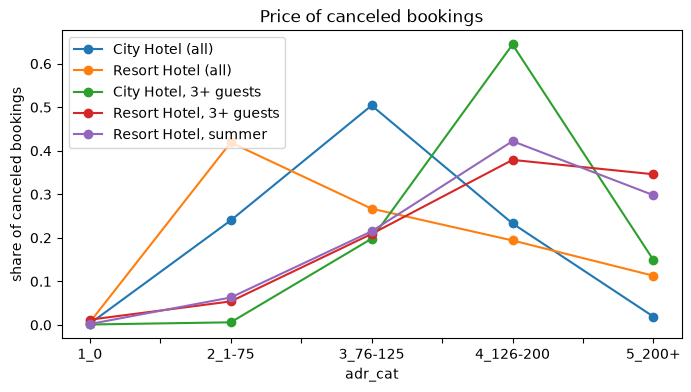

In [3]:
histograms = shapes.drop(columns="n")

# True = the share grows from one category to the next
steps = histograms.diff(axis=1).iloc[:, 1:] > 0
steps.columns = ["0 → 1-75", "1-75 → 76-125", "76-125 → 126-200", "126-200 → 200+"]
display(steps)

ax = histograms.T.plot(marker="o", figsize=(8, 4), title="Price of canceled bookings")
ax.set_xlabel("adr_cat")
ax.set_ylabel("share of canceled bookings");

`S_Up` is the longest run of `True` values in a row.

- The first step is a rise everywhere, because free bookings (`1_0`) are very rare.
- Both hotels as a whole have at most 2 rises, so `S_Up ≥ 2` would accept almost every segment.
- Expensive segments rise up to `4_126-200` (3 rises), so `S_Up ≥ 3` means "bookings over 125 per
  night are the most frequent". The last step is always a fall, so `S_Up = 4` finds nothing.
- The example segments have about 1600–4100 canceled bookings; `Base ≥ 1000` keeps segments of this
  size and removes small, random ones.

## CF-Miner

`deposit_type` is left out on purpose, because non-refundable bookings would dominate the results.

In [4]:
miner = cleverminer(
    df=df,
    proc="CFMiner",
    target="adr_cat",
    quantifiers={
        "S_Up": 3,
        "Base": 1000,
    },
    cond={
        "attributes": [
            {"name": "hotel", "type": "subset", "minlen": 1, "maxlen": 1},
            {"name": "season", "type": "subset", "minlen": 1, "maxlen": 1},
            {"name": "guests_cat", "type": "subset", "minlen": 1, "maxlen": 1},
            {"name": "meal", "type": "subset", "minlen": 1, "maxlen": 1},
        ],
        "minlen": 1,
        "maxlen": 2,
        "type": "con",
    },
    opts={
        "disable_progressbar": True,
    },
)

Cleverminer version 1.2.8.
Progressbar will not be shown.
Progressbar will not be shown.
Starting data preparation ...
Automatically reordering numeric categories ...
Automatically reordering numeric categories ...done
Encoding columns into bit-form...
Encoding columns into bit-form...done
Data preparation finished.
Progressbar will not be shown.
Will go for  CFMiner
Starting to mine rules.


Done. Total verifications : 55, rules 8, times: prep 0.02sec, processing 0.01sec


## Results

In [5]:
miner.print_summary()
miner.print_rulelist()


CleverMiner task processing summary:

Task type : CFMiner
Number of verifications : 55
Number of rules : 8
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


List of rules:
RULEID BASE  S_UP  S_DOWN Condition
     1  3487     3     1 hotel(City Hotel) & guests_cat(3+)
     2  4078     3     1 hotel(Resort Hotel) & season(3_summer)
     3  1584     3     1 hotel(Resort Hotel) & guests_cat(3+)
     4  1241     3     1 season(2_spring) & guests_cat(3+)
     5  2469     3     1 season(3_summer) & guests_cat(3+)
     6  1920     3     1 season(3_summer) & meal(HB)
     7  5071     3     1 guests_cat(3+)
     8  4304     3     1 guests_cat(3+) & meal(BB)



We draw the rules that compare both hotels on the same condition, parties of 3+ guests
(rule 1: City Hotel, rule 3: Resort Hotel), and the only rule not driven by party size
(rule 2: Resort Hotel in summer). The remaining rules have no hotel in the condition or repeat
the party-size pattern.

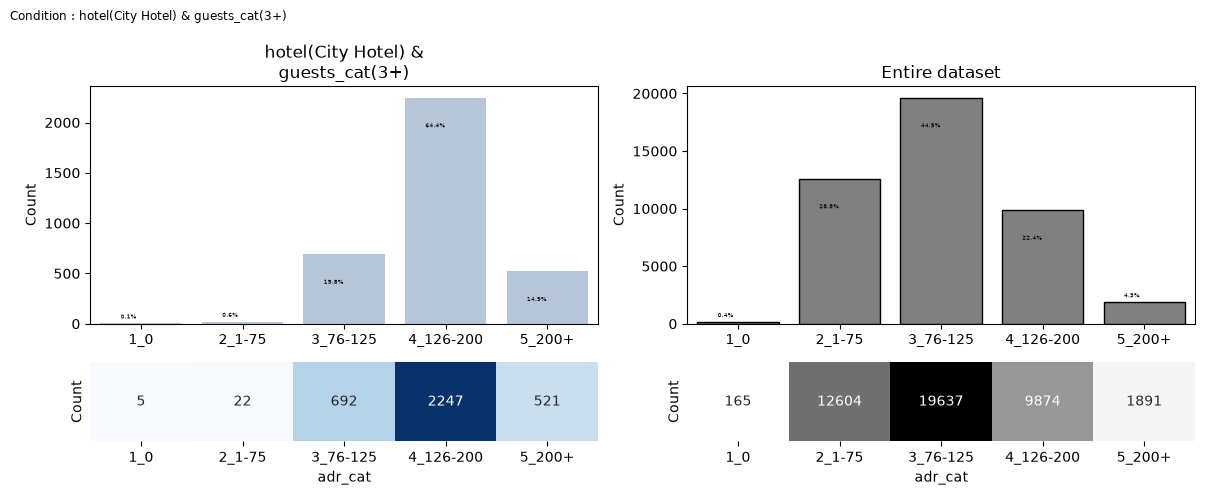

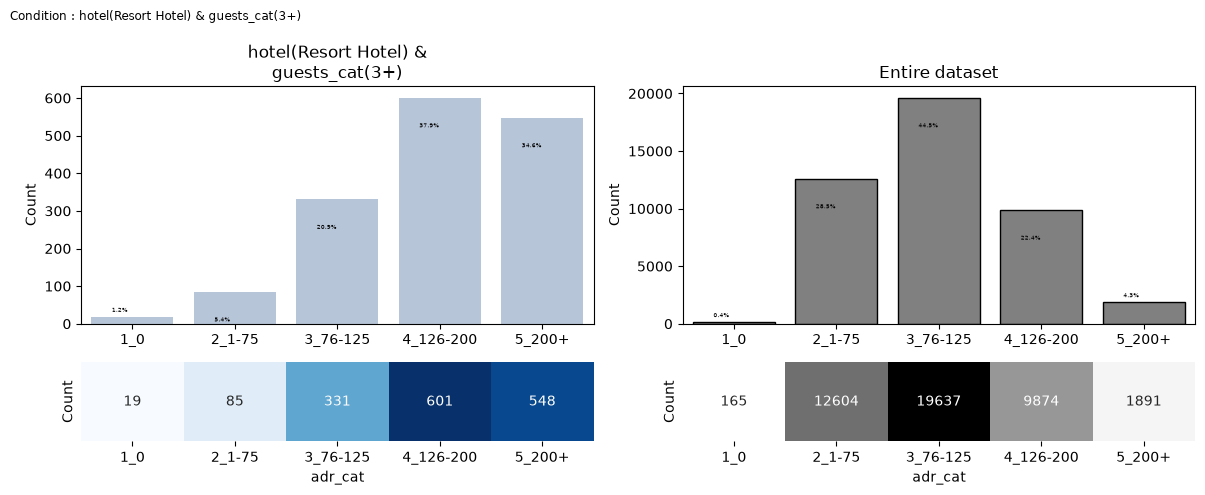

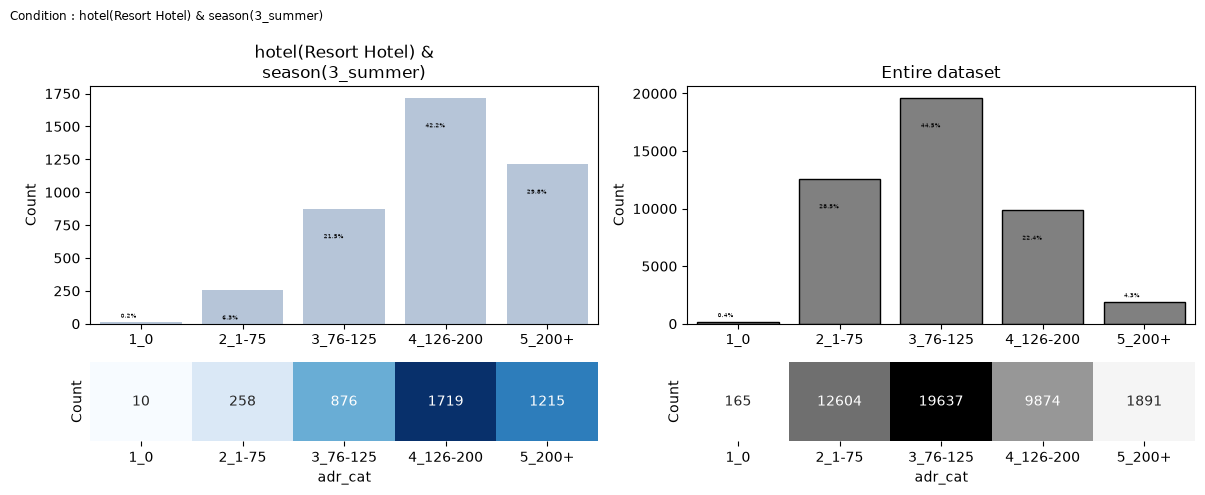

In [6]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)

miner.draw_rule(1)
miner.draw_rule(3)
miner.draw_rule(2)

## Check: canceled vs. not canceled bookings

If kept bookings of a segment are just as expensive, the rule only describes the price level of the
segment. We compare the share of bookings over 125 per night (`4_126-200`, `5_200+`).

In [7]:
expensive = bookings["adr_cat"].isin(["4_126-200", "5_200+"])

comparison = pd.DataFrame({
    name: expensive[mask].groupby(bookings.loc[mask, "is_canceled"]).mean()
    for name, mask in segments.items()
}).T.rename(columns={"0": "not canceled", "1": "canceled"})
comparison["difference (pp)"] = (comparison["canceled"] - comparison["not canceled"]) * 100

comparison.round(3)

is_canceled,not canceled,canceled,difference (pp)
City Hotel (all),0.264,0.253,-1.138
Resort Hotel (all),0.230,0.307,7.676
"City Hotel, 3+ guests",0.712,0.794,8.212
"Resort Hotel, 3+ guests",0.612,0.725,11.314
"Resort Hotel, summer",0.644,0.719,7.553


Cancellation rate in each price category. Only bookings without a deposit are used, because cheap
non-refundable City Hotel bookings are almost always canceled and would distort the picture.

In [8]:
no_deposit = bookings["deposit_type"] == "No Deposit"

pd.crosstab(
    bookings.loc[no_deposit, "adr_cat"],
    bookings.loc[no_deposit, "hotel"],
    values=canceled[no_deposit],
    aggfunc="mean",
).round(3)

hotel,City Hotel,Resort Hotel
adr_cat,,
1_0,0.115,0.201
2_1-75,0.274,0.198
3_76-125,0.296,0.254
4_126-200,0.352,0.316
5_200+,0.356,0.392


## Interpretation

- **CF-Miner:** canceled bookings are mostly over 125 per night for **parties of 3+ guests**
  (both hotels; mostly families) and in the **Resort Hotel in summer**.
- **Check:** in these segments canceled bookings are 8–11 pp more often expensive than kept ones,
  and without deposits the cancellation rate grows with price in both hotels
  (City 27 % → 36 %, Resort 20 % → 39 %). Expensive bookings are therefore riskier,
  so a deposit or stricter cancellation terms for them would protect the highest rates.
- `adr` is a price per room, so larger parties pay more partly because of their size; the results
  describe the price of canceled bookings, not total lost revenue. Associations, not causal effects.
- `has_children` is not used, because 95 % of canceled bookings with children have 3+ guests
  and the rules would only duplicate `guests_cat`.